This notebook shows how to use python scripts to extract data points from a model with an arbitrary grid at the locations and times of the sea ice thickness CDR https://psc.apl.uw.edu/sea_ice_cdr/ and compare them.

Steps:
1. Extract model ice thickness and snow depth at all CDR observations (one step, ~1-2 min per model run).
2. Read the extracted data, compute thickness/draft for all observations (`toThick`), and compare by source, region and season.

In [1]:
import logging
import os
import sys

sys.path.append("/home/axel/ax_python_lib/im")
sys.path.append("/home/axel/ax_python_lib/thickCDR/")
sys.path.append("/home/axel/ax_python_lib/axel_utilities")
import axutil
# various utilities for model data manipulation
import ax_im_utils as im

# load routines from the match_thickCDR_model library
from match_thickCDR_model import *

%load_ext autoreload
%autoreload 2

import pandas as pd
pd.set_option('display.float_format','{:.2f}'.format)
logging.basicConfig(stream=sys.stdout, level=logging.INFO)

ERROR 1: PROJ: proj_create_from_database: Open of /home/axel/miniforge3/envs/pangeo312_m2/share/proj failed


## Choose the model run

Model runs are defined in `RUNS` in `match_thickCDR_model.py`: grid, model directory, file variables (`['hiday','snowday']` daily or `['heff','snow']` monthly) and the maximum distance [km] between an observation and the closest model grid cell.

In [2]:
model_id = "2cfs"
run = RUNS[model_id]
gridName = run["gridName"]
run

{'gridName': '360X276',
 'model_group': '360X276',
 'dist_thresh': 35.0,
 'nt': 47,
 'file_varnames': ['hiday', 'snowday']}

A run that isn't in `RUNS` yet can be added here (or better, in `match_thickCDR_model.py` so it's kept). The model path defaults to `/data/axel0/model_results/<model_group>/<model_id>/nc/`, or set `model_path`:

```python
RUNS["myrun"] = dict(gridName="360X120", model_group="", dist_thresh=25.0, nt=46,
                     file_varnames=["hiday", "snowday"], model_path="/data/axel0/model_results/myrun/nc/")
```

## Extract model data at the CDR observations

Writes `extractDir/<gridName>/<model_id>/<model_id>.extract.<var0>.<var1>.nc` with all sources. Set `extract = True` to (re)run it; it's only needed once per model run (or when the CDR file changes). The same thing from the command line: `python match_thickCDR_model.py <model_id>`.

Observations are matched to the closest grid cell that has model data (within `dist_thresh`) and the closest model time (within 15 days; monthly fields are centered on mid-month).

In [3]:
extract = False
cdr_file = "/home/axel/projects/sea_ice_cdr/idl/axel_cdr/ncdf_dir/uThickCDR_summaries.20251010_V1.0.nc"
if extract:
    driver_onepass(model_id, cdr_file=cdr_file)

## Read the extracted data and compute thickness and draft

The CDR contains draft, thickness and ice+snow thickness, depending on source. `toThick` fills in the others using the model snow depth, and removes the 0.29 m submarine draft bias. It returns a new data set and is safe to call twice.

In [4]:
obsAndModel = readMerged(model_id, gridName)  # all sources; sources=[...] to select
obsAndModel.load()
obsAndModel = toThick(obsAndModel)
print(obsAndModel.sizes["cdr_index"], "matched observations")

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/360X276/2cfs/2cfs.extract.hiday.snowday.nc


INFO:httpx:HTTP Request: GET https://raw.githubusercontent.com/IrishMarineInstitute/awesome-erddap/master/erddaps.json "HTTP/1.1 200 OK"


1919
INFO:root:Removing Submarine Bias


before bias removal: : 2.8513913
After bias removal: : 2.5613914
438938
INFO:root:Number of missing Draft values : 25071


INFO:root:Number of missing THICK values : 25071


INFO:root:Number of missing THICK_ICE_SNOW values : 25071



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]
465404 matched observations


## Statistics by source

CryoSat-AWI is ~90% of all matched observations, so the `ALL` row is dominated by it.

In [5]:
source_stats(obsAndModel)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1395,2.22,2.12,-0.10,0.91,0.63
AWI-GS,134,1.09,0.60,-0.49,0.74,0.59
BGEP,693,1.32,1.97,0.64,0.74,0.87
BIO_LS,36,0.92,1.28,0.36,0.70,0.68
CanCoast,1522,1.27,1.99,0.71,1.81,0.16
CryoSat-AWI,402251,1.27,1.72,0.44,0.70,0.74
Davis_St,67,0.74,0.62,-0.12,0.50,0.78
ICESAT1-G,29393,1.91,2.08,0.17,0.95,0.36
IOS-CHK,26,1.26,1.76,0.50,0.62,0.92
IOS-EBS,382,1.40,1.46,0.07,0.78,0.65


Draft comparison (model draft computed from model thickness and snow):

In [6]:
source_stats(obsAndModel, draft=True)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1395,2.48,2.39,-0.09,0.82,0.78
AWI-GS,134,1.03,0.97,-0.06,0.78,0.58
BGEP,693,1.24,2.22,0.98,1.11,0.82
BIO_LS,36,0.88,1.58,0.70,1.02,0.71
CanCoast,1522,1.64,2.29,0.65,1.63,0.55
CryoSat-AWI,402251,1.78,2.18,0.40,0.63,0.86
Davis_St,67,0.69,0.80,0.11,0.48,0.79
ICESAT1-G,29393,2.51,2.66,0.15,0.85,0.57
IOS-CHK,26,1.20,2.11,0.91,1.05,0.91
IOS-EBS,382,1.29,1.60,0.31,0.89,0.64


## Compare several model runs

Bias (model - observation) by source for runs that have been extracted.

In [7]:
runs = ["1c", "2c", "2cfs"]
tables = {}
for mid in runs:
    ds = readMerged(mid, RUNS[mid]["gridName"])
    ds.load()
    tables[mid] = source_stats(toThick(ds))
pd.concat({mid: t[["n", "bias(mod-obs)", "rmse", "r"]] for mid, t in tables.items()}, axis=1)

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/912X672/1c/1c.extract.heff.snow.nc


1917
INFO:root:Removing Submarine Bias


before bias removal: : 2.8518257
After bias removal: : 2.5618258
417417
INFO:root:Number of missing Draft values : 24826


INFO:root:Number of missing THICK values : 24826


INFO:root:Number of missing THICK_ICE_SNOW values : 24826



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025033 21025034 21025035]


... (9 outputs left out)

INFO:root:Number of missing THICK values : 25071


INFO:root:Number of missing THICK_ICE_SNOW values : 25071



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]


1c                                2c                     \
                   n bias(mod-obs) rmse    r         n bias(mod-obs) rmse   
AIR-EM          1229          1.07 1.51 0.67   1224.00          0.22 0.96   
AWI-GS           134          0.90 1.17 0.49       NaN           NaN  NaN   
BGEP             693          0.73 0.86 0.82    693.00          0.31 0.57   
BIO_LS            36          0.57 1.02 0.29     36.00          0.01 0.57   
CanCoast         776          1.06 1.50 0.25    125.00          1.92 2.33   
CryoSat-AWI   381652          0.88 1.14 0.73 381652.00          0.51 0.76   
Davis_St          67          0.10 0.52 0.75     67.00          0.01 0.52   
ICESAT1-G      29220          0.93 1.31 0.63  29220.00          0.39 0.98   
IOS-CHK           26          0.62 0.70 0.94     26.00          0.26 0.40   
IOS-EBS          382          0.23 1.02 0.56      9.00         -0.47 1.04   
IceBridge-QL    1517          0.80 1.11 0.74   1517.00          0.23 0.77   
IceBridge-V2     933          0.90 1.42 0.55    933.00          0.25 0.95   
NPEO              64          0.02 0.91 0.22     43.00         -0.62 1.12   
UKSUB-AN         149          1.02 1.88 0.59       NaN           NaN  NaN   
USSUB-AN         646         -0.06 0.72 0.77     58.00         -0.14 0.56   
USSUB-DG        1122          0.02 0.83 0.66    121.00          0.49 0.63   
ALL           418646          0.88 1.15 0.73 415724.00          0.50 0.78   

                     2cfs                          
                r       n bias(mod-obs) rmse    r  
AIR-EM       0.70    1395         -0.10 0.91 0.63  
AWI-GS        NaN     134         -0.49 0.74 0.59  
BGEP         0.82     693          0.64 0.74 0.87  
BIO_LS       0.69      36          0.36 0.70 0.68  
CanCoast     0.27    1522          0.71 1.81 0.16  
CryoSat-AWI  0.76  402251          0.44 0.70 0.74  
Davis_St     0.75      67         -0.12 0.50 0.78  
ICESAT1-G    0.55   29393          0.17 0.95 0.36  
IOS-CHK      0.96      26          0.50 0.62 0.92  
IOS-EBS      0.34     382          0.07 0.78 0.65  
IceBridge-QL 0.73    1518         -0.09 0.82 0.60  
IceBridge-V2 0.57     933         -0.17 0.89 0.46  
NPEO         0.43      64         -1.00 1.31 0.32  
UKSUB-AN      NaN     149         -1.09 1.85 0.69  
USSUB-AN     0.85     646         -0.54 1.01 0.67  
USSUB-DG     0.55    1124         -0.40 0.97 0.52  
ALL          0.75  440333          0.42 0.73 0.71

## Scatter plot and histograms for observed and modeled ice thickness

Model has Nan:  False
Observations have Nan: False
[0.8112471  0.71250938]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.545
Model:                            OLS   Adj. R-squared:                  0.545
Method:                 Least Squares   F-statistic:                 4.814e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:21:36   Log-Likelihood:            -2.8322e+05
No. Observations:              402251   AIC:                         5.665e+05
Df Residuals:                  402249   BIC:                         5.665e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

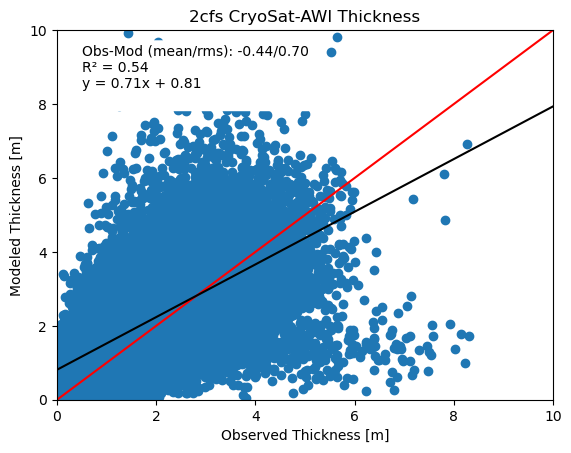

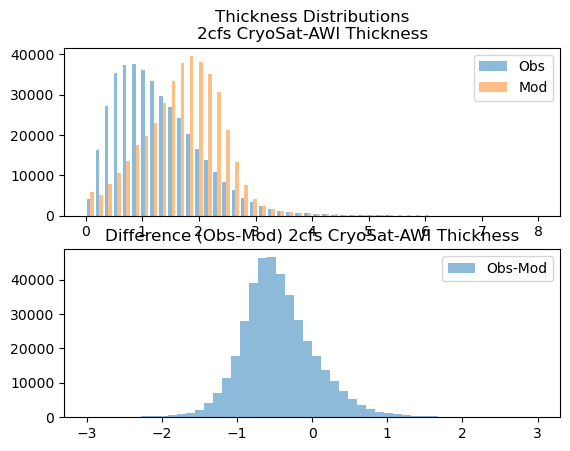

In [8]:
select_sources = ["CryoSat-AWI"]
sub = obsAndModel.isel(cdr_index=obsAndModel.SOURCE.isin(select_sources).values)
title = model_id + " " + ":".join(select_sources) + " Thickness"
fig, ax, results = scatter_plot(sub, model_id, title=title, draft=False)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Same for draft

Model has Nan:  False
Observations have Nan: False
[0.83990317 1.10943614]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.675
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     1434.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          9.97e-171
Time:                        12:21:37   Log-Likelihood:                -528.20
No. Observations:                 693   AIC:                             1060.
Df Residuals:                     691   BIC:                             1069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

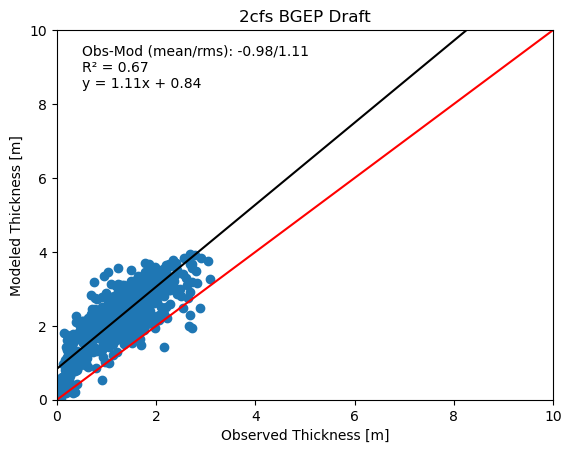

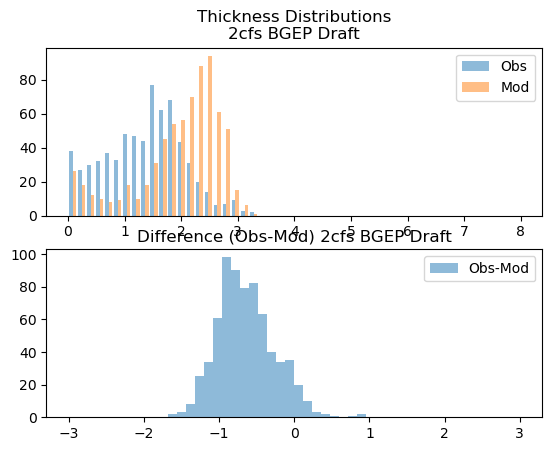

In [9]:
select_sources = ["BGEP"]
sub = obsAndModel.isel(cdr_index=obsAndModel.SOURCE.isin(select_sources).values)
title = model_id + " " + ":".join(select_sources) + " Draft"
fig, ax, results = scatter_plot(sub, model_id, title=title, draft=True)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Demonstrate how subsetting by space can be done

In [10]:
import geopandas as gpd
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature 
from shapely.geometry import Point,MultiPoint,Polygon, mapping
from model_maps_arctic import map_arctic_ortho,map_arctic_region,arctic_map_outline,ax_reset_norm

Remove the satellite sources (they dominate by number) and keep the mean values (`Mean Max Min Sigma` = 0), which is necessary for creating the pandas data frame.

In [11]:
satellite = ["CryoSat-AWI", "ENVISAT", "ICESAT1-G"]
insitu = obsAndModel.isel(cdr_index=~obsAndModel.SOURCE.isin(satellite).values)
sub = insitu.isel({"Mean Max Min Sigma": 0})
sub["lon"] = axutil.lonTo180(sub.lon)  # appears necessary otherwise doesn't work.
df = sub.to_dataframe()
geometry = gpd.points_from_xy(df["lon"], df["lat"])

## Create a geopanda data frame from the geometry data created above

In [12]:
gdf_points = gpd.GeoDataFrame(df,geometry=geometry, crs="EPSG:4326")

## Now define a Polygon in Lon,lat Space and create a geopanda polygon 

In [13]:
polygon = Polygon([(-100, 70), (-100, 82), (-180, 82), (-180, 70)])
gdf_polygon = gpd.GeoDataFrame(geometry=[polygon], crs="EPSG:4326")

## Check if the list of points (cdr observations) is inside the polygon defined above

In [14]:
points_within_polygon = gpd.sjoin(gdf_points, gdf_polygon, predicate='within')

## For checking that the subsetting works, plot the area that is selected

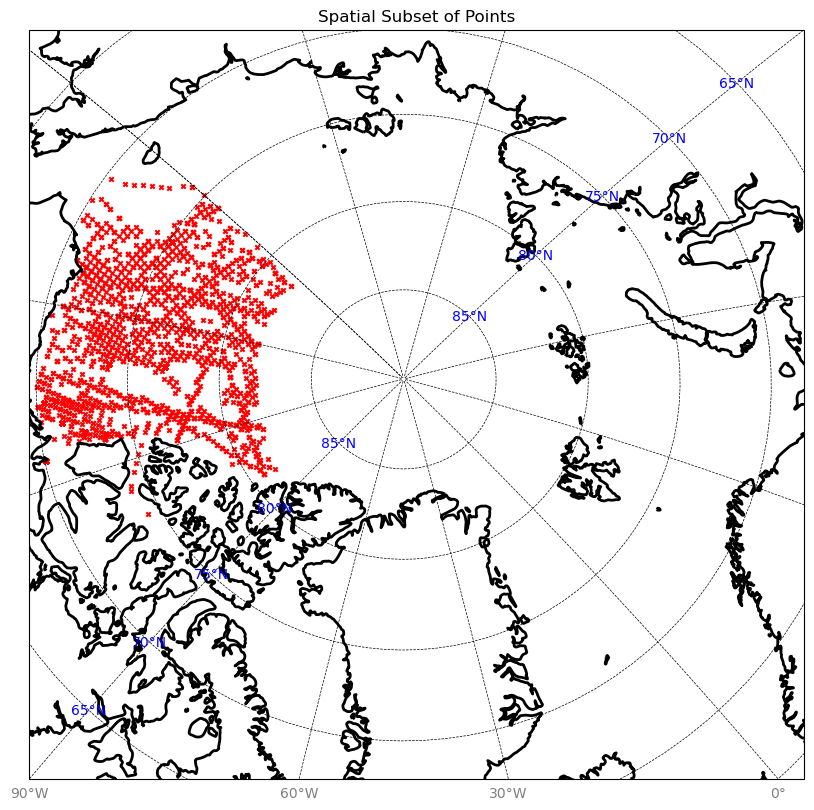

In [15]:
ax,fig,gl=arctic_map_outline("Spatial Subset of Points",land_fill=False)
plons=points_within_polygon['geometry'].x
plats=points_within_polygon['geometry'].y
ax.scatter(x=plons,y=plats,s=10,marker='x',color='red',transform=ccrs.PlateCarree())
plt.show()

## Now create the scatter plot and histogram of the subset

Model has Nan:  False
Observations have Nan: False
[1.21972208 0.50533946]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.453
Model:                            OLS   Adj. R-squared:                  0.453
Method:                 Least Squares   F-statistic:                     2663.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:21:41   Log-Likelihood:                -2548.1
No. Observations:                3213   AIC:                             5100.
Df Residuals:                    3211   BIC:                             5112.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

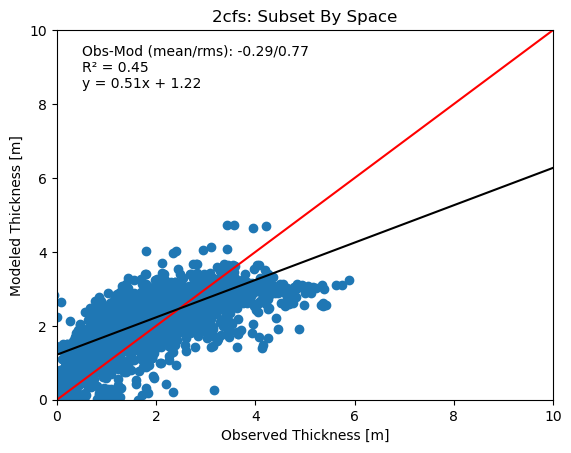

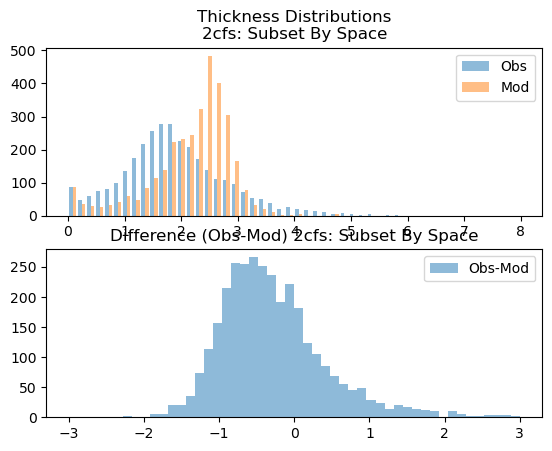

In [16]:
title = model_id + ": Subset By Space"
cdr_index = points_within_polygon.index
sub = insitu.sel(cdr_index=cdr_index)
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Winter and summer

Model has Nan:  False
Observations have Nan: False
[1.98912609 0.23694416]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.252
Method:                 Least Squares   F-statistic:                     678.6
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          3.59e-129
Time:                        12:21:41   Log-Likelihood:                -767.02
No. Observations:                2016   AIC:                             1538.
Df Residuals:                    2014   BIC:                             1549.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

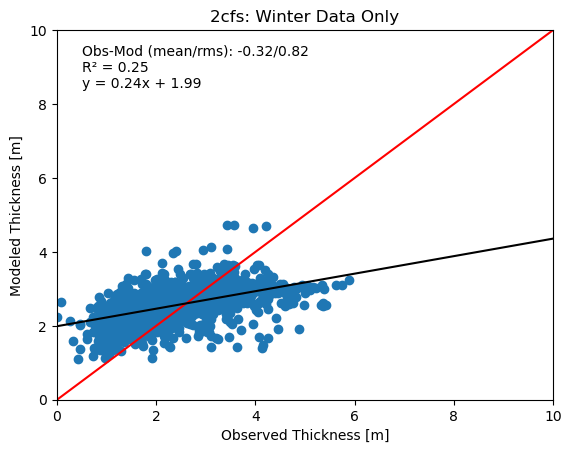

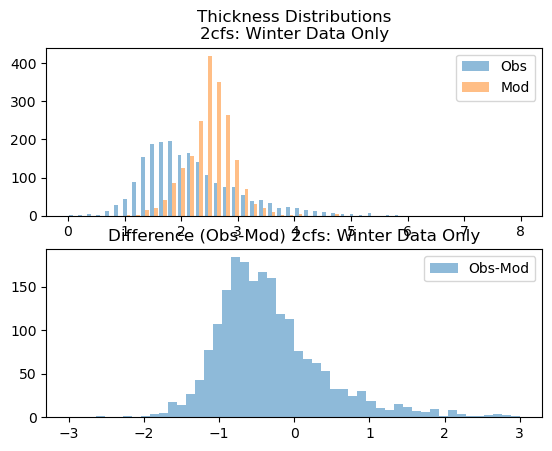

In [17]:
def is_winter(month):
    return (month >= 1) & (month <= 4)

sub = insitu.sel(cdr_index=cdr_index)
sub = sub.isel(cdr_index=is_winter(sub["obs_time.month"]))
title = model_id + ": Winter Data Only"
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

Model has Nan:  False
Observations have Nan: False
[0.71030733 0.63209281]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.526
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     1211.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          3.94e-179
Time:                        12:21:42   Log-Likelihood:                -910.57
No. Observations:                1094   AIC:                             1825.
Df Residuals:                    1092   BIC:                             1835.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

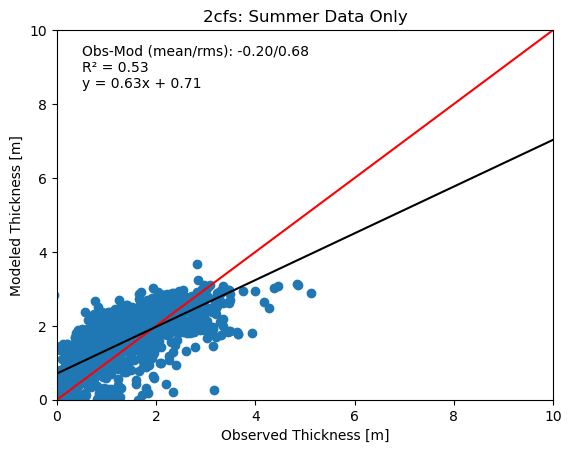

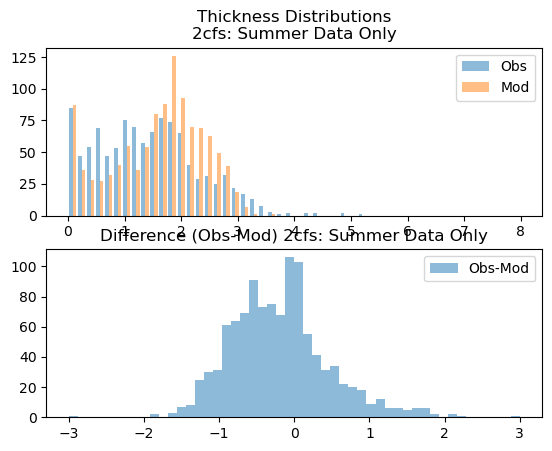

In [18]:
def is_summer(month):
    return (month >= 5) & (month <= 11)

sub = insitu.sel(cdr_index=cdr_index)
sub = sub.isel(cdr_index=is_summer(sub["obs_time.month"]))
title = model_id + ": Summer Data Only"
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

Statistics by source for the summer subset:

In [19]:
source_stats(sub)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1,5.13,2.88,-2.24,2.24,NaN
BGEP,410,1.14,1.69,0.55,0.69,0.87
CanCoast,47,1.27,1.26,-0.00,0.52,0.69
IOS-CHK,16,0.96,1.45,0.49,0.64,0.92
IOS-EBS,228,1.26,1.06,-0.20,0.72,0.74
USSUB-AN,184,1.77,1.98,0.21,0.69,0.73
USSUB-DG,208,1.75,1.71,-0.04,0.65,0.71
ALL,1094,1.39,1.59,0.20,0.68,0.73
